In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [24]:
df = pd.read_csv(r"/content/global_fuel_prices_2020_2026.csv")
print("First 5 rows of the dataset:")
display(df.head())
display(df.tail())


print("\nDataset Information:")
df.info()


print("\nMissing values in each column:")
print(df.isnull().sum())


print("\nSummary Statistics:")
display(df.describe())

cv_percent = (df.std(numeric_only=True) / df.mean(numeric_only=True)) * 100
print("\nOscillation:")
print(cv_percent)

First 5 rows of the dataset:


,date,country,region,income_level,subsidy_level,petrol_usd_liter,diesel_usd_liter,lpg_usd_liter,brent_crude_usd,tax_percentage
0,2020-01-06,United States,North America,High,Low,1.465,1.289,1.093,65.75,59.6
1,2020-01-13,United States,North America,High,Low,1.435,1.319,1.077,65.54,27.6
2,2020-01-20,United States,North America,High,Low,1.446,1.329,1.080,66.51,62.3
3,2020-01-27,United States,North America,High,Low,1.488,1.359,1.125,68.79,44.8
4,2020-02-03,United States,North America,High,Low,1.457,1.341,1.111,68.44,51.4


,date,country,region,income_level,subsidy_level,petrol_usd_liter,diesel_usd_liter,lpg_usd_liter,brent_crude_usd,tax_percentage
27463,2026-03-09,Rwanda,Africa,Low,Low,3.036,2.849,2.294,130.0,62.3
27464,2026-03-16,Rwanda,Africa,Low,Low,3.020,2.861,2.248,130.0,43.3
27465,2026-03-23,Rwanda,Africa,Low,Low,3.072,2.825,2.334,130.0,64.1
27466,2026-03-30,Rwanda,Africa,Low,Low,3.045,2.816,2.282,130.0,43.7
27467,2026-04-06,Rwanda,Africa,Low,Low,3.064,2.846,2.296,130.0,63.7



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27468 entries, 0 to 27467
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              27468 non-null  object 
 1   country           27468 non-null  object 
 2   region            27468 non-null  object 
 3   income_level      27468 non-null  object 
 4   subsidy_level     27468 non-null  object 
 5   petrol_usd_liter  27468 non-null  float64
 6   diesel_usd_liter  27468 non-null  float64
 7   lpg_usd_liter     27468 non-null  float64
 8   brent_crude_usd   27468 non-null  float64
 9   tax_percentage    27468 non-null  float64
dtypes: float64(5), object(5)
memory usage: 2.1+ MB

Missing values in each column:
date                0
country             0
region              0
income_level        0
subsidy_level       0
petrol_usd_liter    0
diesel_usd_liter    0
lpg_usd_liter       0
brent_crude_usd     0
tax_percentage      0
d

,petrol_usd_liter,diesel_usd_liter,lpg_usd_liter,brent_crude_usd,tax_percentage
count,27468.000000,27468.000000,27468.000000,27468.000000,27468.000000
mean,2.281915,2.133760,1.711473,106.686453,26.774468
std,1.540612,1.465058,1.155543,18.972391,17.203349
min,0.010000,0.010000,0.010000,47.970000,0.000000
25%,0.926000,0.858000,0.695000,101.140000,13.500000
50%,2.116500,1.954500,1.588000,112.270000,23.400000
75%,3.457000,3.231000,2.590000,119.410000,38.900000
max,6.779000,6.240000,5.100000,130.000000,65.000000



Oscillation:
petrol_usd_liter    67.513998
diesel_usd_liter    68.660832
lpg_usd_liter       67.517493
brent_crude_usd     17.783317
tax_percentage      64.252813
dtype: float64


In [27]:

df['date'] = pd.to_datetime(df['date'])

#if df.isnull().values.any(): # كدا كدا مفيش missing values  الحمدلله هي الداتا سيت كدا
    #df = df.dropna()
#else:
    #print("No missing values found!")


In [31]:
print(f"Number of unique countries: {df['country'].nunique()}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")

avg_petrol_region = df.groupby('region')['petrol_usd_liter'].mean().sort_values(ascending=False)
print("\nAverage Petrol Price by Region (USD/Liter):")
print(avg_petrol_region)

Std_Petrol_Region = df.groupby('region')['petrol_usd_liter'].std()
#print("\nStandard Deviation of Petrol Prices by Region (USD/Liter):")
#print(Std_Petrol_Region)

Oscillation = (Std_Petrol_Region / avg_petrol_region) * 100
print("\nOscillation of Petrol Prices by Region:")
print(Oscillation)


Number of unique countries: 84
Date range: 2020-01-06 to 2026-04-06

Average Petrol Price by Region (USD/Liter):
region
Europe           3.701695
Oceania          3.655203
Asia             2.140571
North America    2.064176
Africa           1.549482
South America    1.425393
Middle East      1.225935
Name: petrol_usd_liter, dtype: float64

Oscillation of Petrol Prices by Region:
region
Africa            61.102465
Asia              67.700730
Europe            32.748928
Middle East      120.417562
North America     43.001986
Oceania           18.880142
South America     76.014499
Name: petrol_usd_liter, dtype: float64


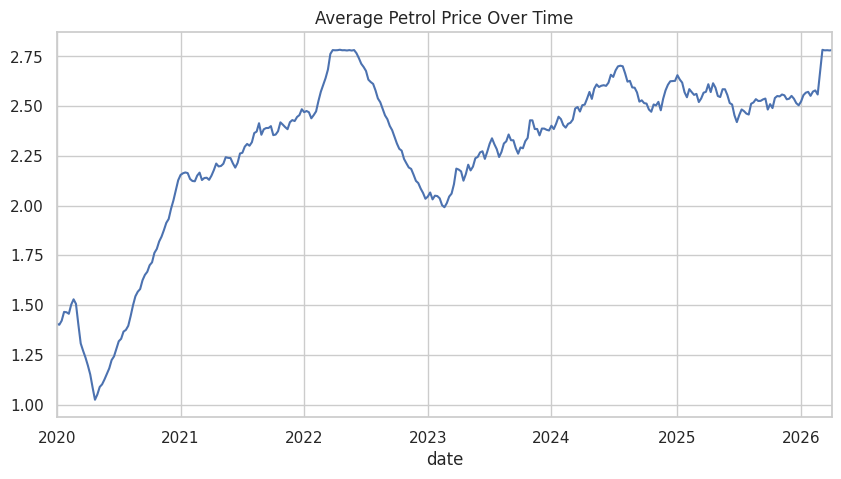

In [35]:
df.groupby('date')['petrol_usd_liter'].mean().plot(figsize=(10,5))
plt.title("Average Petrol Price Over Time")
plt.show()

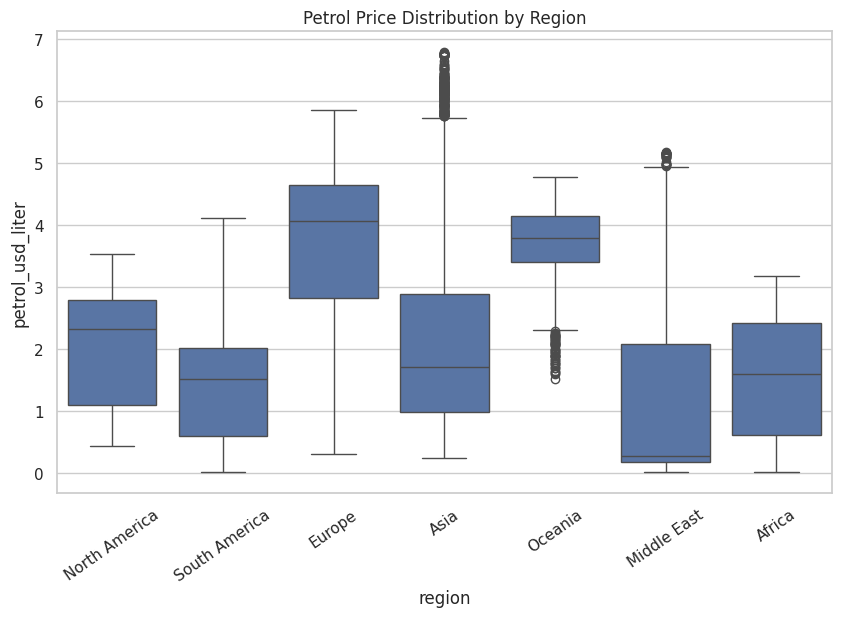

In [37]:

plt.figure(figsize=(10,6))
sns.boxplot(x='region', y='petrol_usd_liter', data=df)

plt.xticks(rotation=35)
plt.title("Petrol Price Distribution by Region")
plt.show()

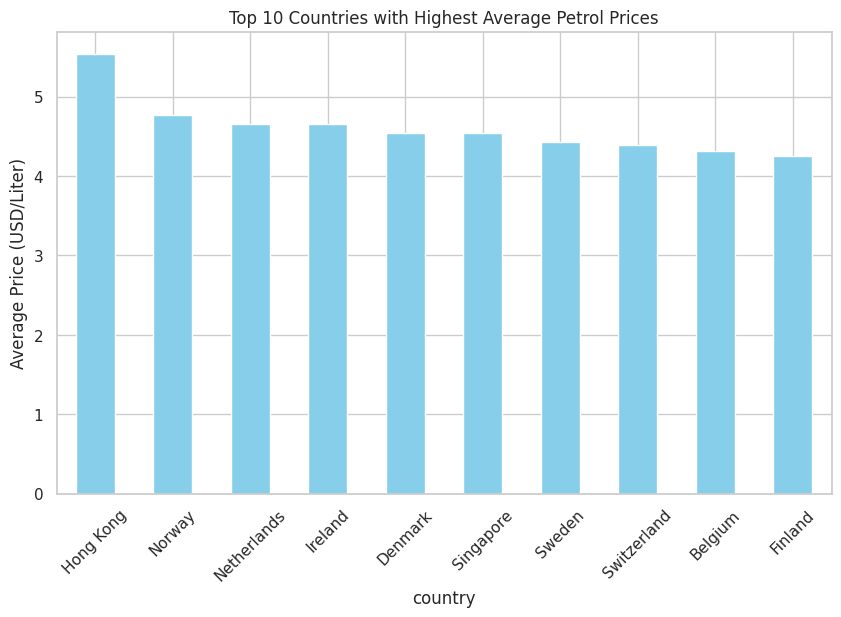

In [16]:
top_countries = df.groupby('country')['petrol_usd_liter'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
top_countries.plot(kind='bar', color='skyblue')
plt.title('Top 10 Countries with Highest Average Petrol Prices')
plt.ylabel('Average Price (USD/Liter)')
plt.xticks(rotation=45)
plt.show()

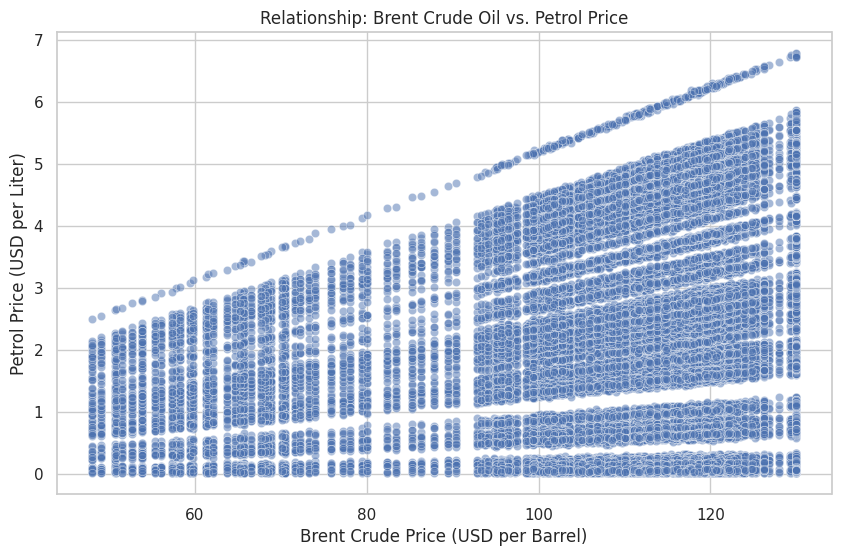

Correlation coefficient: 0.26


In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='brent_crude_usd', y='petrol_usd_liter', alpha=0.5)
plt.title('Relationship: Brent Crude Oil vs. Petrol Price')
plt.xlabel('Brent Crude Price (USD per Barrel)')
plt.ylabel('Petrol Price (USD per Liter)')
plt.show()

correlation = df['brent_crude_usd'].corr(df['petrol_usd_liter'])
print(f"Correlation coefficient: {correlation:.2f}")

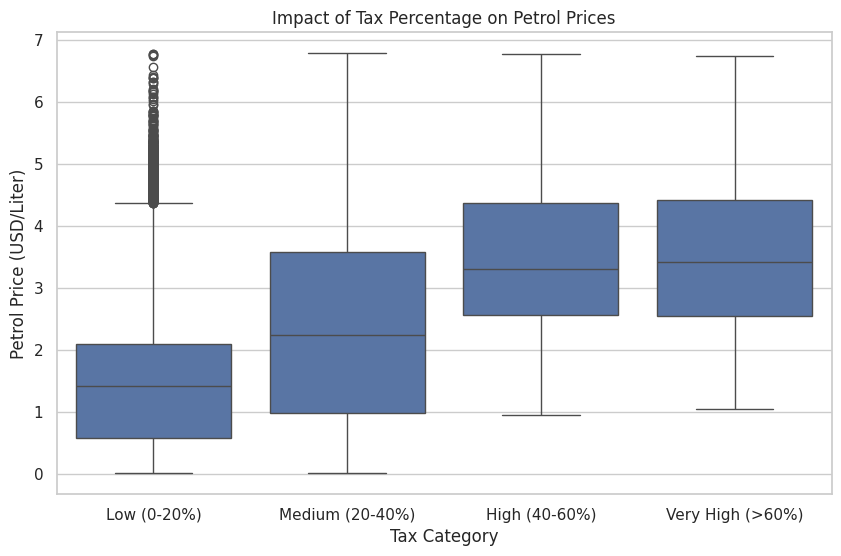

In [18]:
df['tax_group'] = pd.cut(df['tax_percentage'], bins=[0, 20, 40, 60, 100], labels=['Low (0-20%)', 'Medium (20-40%)', 'High (40-60%)', 'Very High (>60%)'])

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='tax_group', y='petrol_usd_liter')
plt.title('Impact of Tax Percentage on Petrol Prices')
plt.xlabel('Tax Category')
plt.ylabel('Petrol Price (USD/Liter)')
plt.show()